In [1]:
import numpy as np
seed = 42
np.random.seed(seed)

In [2]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_test.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9
0,-1.450948,4.181026,0.315353,-0.251254,3.712738,Copper,23.418877,2.426998,NaN
1,1.910953,-2.855684,-0.689987,-3.304068,1.586565,Aluminum,25.876919,-3.576890,-5.457079
2,0.711879,-0.310080,-0.842278,-2.649052,1.280301,Aluminum,2.122538,-4.443754,-0.220739
3,-0.247738,1.672883,1.714396,0.778677,3.796557,Aluminum,1.578427,-2.403209,-0.414437
4,0.361466,2.905622,2.614933,0.482835,2.228428,Titanium,9.168415,-3.714651,1.050284


In [3]:
import numpy as np
X = pd.DataFrame()
X_final = df_test.copy()

X["X1"] = [np.random.normal(loc=0, scale=1) for i in range(50000)]

X["X2"] = [np.random.uniform(low=-5, high=5) for i in range(50000)]

opts = ['Copper', 'Aluminum', 'Titanium', 'Tungsten']
X["X6"] = [np.random.choice(opts, p=[0.1, 0.2, 0.3, 0.4]) for i in range(50000)]

X['X7'] = X.X2.apply(lambda x : (2*(x**2)) - (3*x) + 1)

def get_num():
    flip = np.random.choice(["opt1", "opt2"], p=[0.7, 0.3])
    if flip == "opt1":
        return np.random.normal(loc = -3, scale = 1)
    if flip == "opt2":
        return np.random.normal(loc = 3, scale = 1)

X['X8'] = [get_num() for i in range(50000)]

x9 = []
for _, row in X.iterrows():
    if row.X6 != 'Copper':
        x9.append(row.X1*row.X2)
    else:
        x9.append(None)
X['X9'] = x9

X.head()

,X1,X2,X6,X7,X8,X9
0,0.496714,-4.972295,Tungsten,65.364319,-5.192895,-2.469809
1,-0.138264,-1.174774,Titanium,7.284507,2.735406,0.162429
2,0.647689,4.140493,Titanium,22.865882,3.593988,2.681750
3,1.523030,4.477549,Aluminum,27.664247,-3.460842,6.819441
4,-0.234153,-4.464408,Tungsten,54.255091,-2.976796,1.045356


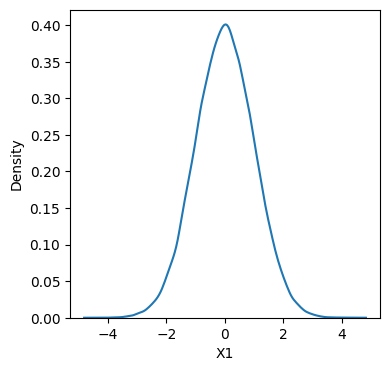

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
sns.kdeplot(X.X1)
plt.show()

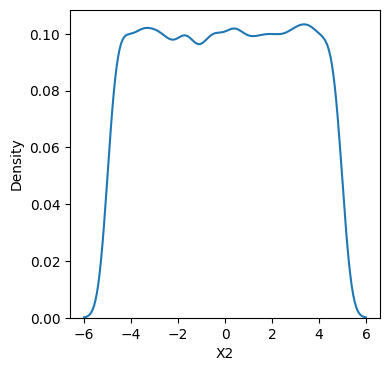

In [5]:
plt.figure(figsize=(4, 4))
sns.kdeplot(X.X2)
plt.show()

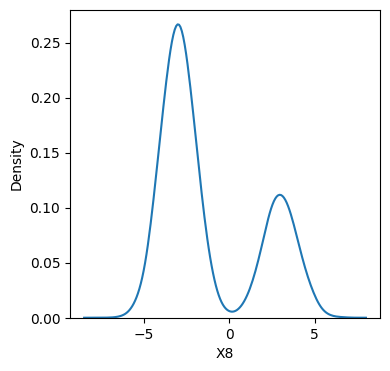

In [6]:
plt.figure(figsize=(4, 4))
sns.kdeplot(X.X8)
plt.show()

In [7]:
features = [col for col in X]

X = X
y = df_train.Y

X_final = X_final[features]

na_cols = ['X9']
cat_cols = ['X6']

from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
X[na_cols] = pd.DataFrame(imputer.fit_transform(X[na_cols]), columns=na_cols)
X_final[na_cols] = pd.DataFrame(imputer.transform(X_final[na_cols]), columns=na_cols)

X = pd.get_dummies(X, columns=cat_cols)
X_final = pd.get_dummies(X_final, columns=cat_cols)

X.head()

,X1,X2,X7,X8,X9,X6_Aluminum,X6_Copper,X6_Titanium,X6_Tungsten
0,0.496714,-4.972295,65.364319,-5.192895,-2.469809,False,False,False,True
1,-0.138264,-1.174774,7.284507,2.735406,0.162429,False,False,True,False
2,0.647689,4.140493,22.865882,3.593988,2.681750,False,False,True,False
3,1.523030,4.477549,27.664247,-3.460842,6.819441,True,False,False,False
4,-0.234153,-4.464408,54.255091,-2.976796,1.045356,False,False,False,True


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

model = HistGradientBoostingRegressor()

cross_val_score(model, X, y, cv=3, scoring='neg_root_mean_squared_error').mean()

np.float64(-6.438432037554605)

In [9]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [10]:
df_preds = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": range(10000),
    "answer": y_preds
})

df_preds

,subtaskID,datapointID,answer
0,1,0,14.891485
1,1,1,24.998520
2,1,2,3.599618
3,1,3,-0.338311
4,1,4,10.018061
...,...,...,...
9995,1,9995,2.157082
9996,1,9996,2.161619
9997,1,9997,20.006375
9998,1,9998,-6.305515


In [11]:
df_preds.to_csv("submission.csv", index=False)